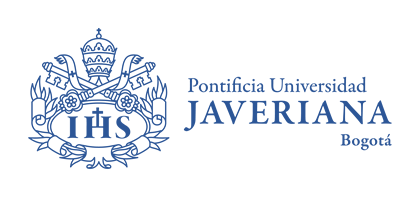

# Aprendizaje de máquina - Ejercicio PCA
Los modelos de reducción dimensional permiten reducir la redundancia de los datos de entrada, proyectando los datos a un espacio dimensional menor que permite visualizar los resultados y eventualmente usar otros modelos a partir de estos datos.

Los objetivos de este notebook son los siguientes:

*   Ver algunos ejemplos de uso de PCA utilizando la librería sklearn en python
*   Aplicar PCA para reducción dimensional sobre un dataset multivariado


**Créditos**

Este notebook esta adaptado a partir del contenido del libro  Python Data Science Handbook de Jake VanderPlas disponible en Github [on GitHub](https://github.com/jakevdp/PythonDataScienceHandbook).

* El libro esta liberado bajo licencia creative commons [CC-BY-NC-ND license](https://creativecommons.org/licenses/by-nc-nd/3.0/us/legalcode)

En este notebook revisaremos el uso de PCA a diversos problemas  como visualización, filtrado de ruido, ingeniería de características entre otros.

Iniciamos importando algunas librerias

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()

## Introducción a  PCA

Consideremos los siguientes puntos

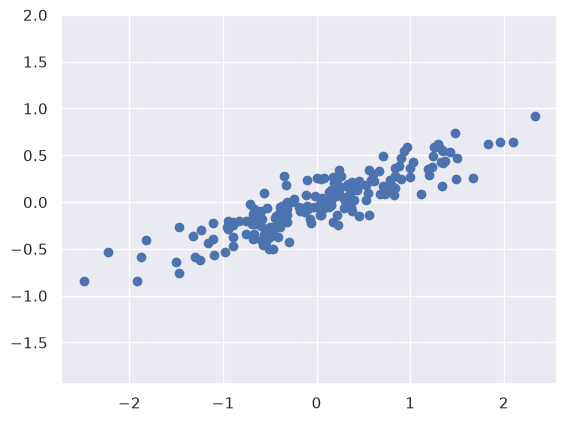

In [2]:
rng = np.random.RandomState(1)
X = np.dot(rng.rand(2, 2), rng.randn(2, 200)).T
plt.scatter(X[:, 0], X[:, 1])
plt.axis('equal');

En PCA, nuestro objetivo es encontrar los principales ejes ortogonales sobre los cuáles podemos reflejar el conjunto de datos original .


Para usar ``PCA`` en scikit-learn, podemos usar el siguiente código:

In [3]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca.fit(X)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",2
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

El método fit aprende los eigenvalores y eigenvectores que nos sirven para reflejar los datos sobre un nuevo espacio vectorial, podemos accederlo usando los siguientes métodos:

In [4]:
print(pca.components_)

[[ 0.94446029  0.32862557]
 [-0.32862557  0.94446029]]


In [5]:
# Deberían ser vectores ortogonales
np.round(np.dot(pca.components_[0], pca.components_[1]),4)

np.float64(0.0)

Varianza explicada por cada nuevo eigenvector

In [6]:
print(pca.explained_variance_)

[0.7625315 0.0184779]


In [7]:
pca.explained_variance_/np.sum(pca.explained_variance_)

array([0.97634101, 0.02365899])

Porcentaje de varianza explicada por cada eigenvector

In [8]:
print(pca.explained_variance_ratio_)

[0.97634101 0.02365899]


In [9]:
pca.mean_

array([ 0.03351168, -0.00408072])

Reflejemos en un gráfico los eigenvectores, con una magnitud proporcional al eigenvalor del gráfico.


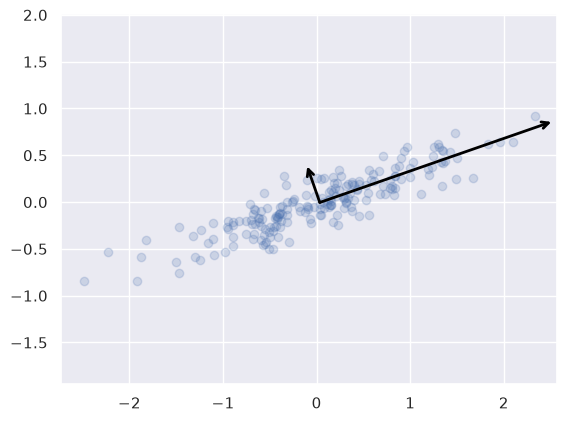

In [10]:
def draw_vector(v0, v1, ax=None):
    ax = ax or plt.gca()
    arrowprops=dict(arrowstyle='->',
                    linewidth=2,
                    shrinkA=0, shrinkB=0, color="black")
    ax.annotate('', v1, v0, arrowprops=arrowprops)

# plot data
plt.scatter(X[:, 0], X[:, 1], alpha=0.2)
for length, vector in zip(pca.explained_variance_, pca.components_):
    v = vector * 3 * np.sqrt(length)
    draw_vector(pca.mean_, pca.mean_ + v)
plt.axis('equal');

In [11]:
print(pca.components_)

[[ 0.94446029  0.32862557]
 [-0.32862557  0.94446029]]


In [12]:
X[0:5]

array([[-0.62530162, -0.17006366],
       [ 0.96069503,  0.5909006 ],
       [-0.59854339, -0.40259339],
       [-2.22805938, -0.53257674],
       [-0.46143006, -0.49886724]])

In [13]:
pca.transform(X[0:5])

array([[-0.67676923,  0.0597386 ],
       [ 1.07121393,  0.25724006],
       [-0.72791236, -0.16866994],
       [-2.30964136,  0.24406657],
       [-0.63005232, -0.30465571]])

In [14]:
np.dot(X[0:5]-pca.mean_,pca.components_.T)


array([[-0.67676923,  0.0597386 ],
       [ 1.07121393,  0.25724006],
       [-0.72791236, -0.16866994],
       [-2.30964136,  0.24406657],
       [-0.63005232, -0.30465571]])

Estos componentes representan la mejor rotación para maximizar la varianza de las dimensiones, y su magnitud nos indica qué tan importantes son.

Si dibujamos los componentes principales y los datos proyectados a estos componentes, podemos evidenciar qué pasa con la tranformación de los datos.

[Text(0.5, 0, 'component 1'),
 Text(0, 0.5, 'component 2'),
 Text(0.5, 1.0, 'principal components'),
 (-5.0, 5.0),
 (-3.0, 3.1)]

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


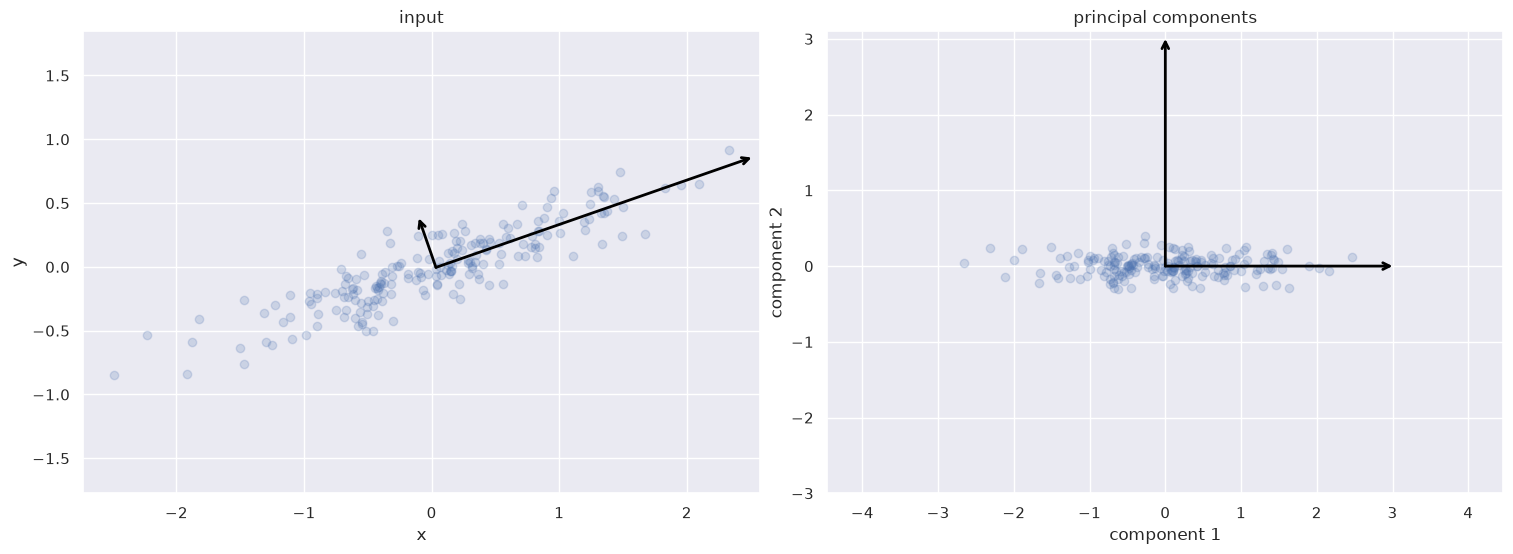

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

# plot data
ax[0].scatter(X[:, 0], X[:, 1], alpha=0.2)
for length, vector in zip(pca.explained_variance_, pca.components_):
    v = vector * 3 * np.sqrt(length)
    draw_vector(pca.mean_, pca.mean_ + v, ax=ax[0])
ax[0].axis('equal');
ax[0].set(xlabel='x', ylabel='y', title='input')

# plot principal components
X_pca = pca.transform(X)
ax[1].scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.2)
draw_vector([0, 0], [0, 3], ax=ax[1])
draw_vector([0, 0], [3, 0], ax=ax[1])
ax[1].axis('equal')
ax[1].set(xlabel='component 1', ylabel='component 2',
          title='principal components',
          xlim=(-5, 5), ylim=(-3, 3.1))

A este tipo de transformaciones se les conoce como  una *transformación afín*, (rotar, escalar y transladar cada punto).


In [16]:
print(f"Covariance matrix of transformed data:")
np.round(np.cov(pca.transform(X).T),6)

Covariance matrix of transformed data:


array([[ 0.762532, -0.      ],
       [-0.      ,  0.018478]])

Como se puede observar en la matriz de covarianza, los elementos fuera de la diagonal están muy cerca de cero, lo que indica que los componentes principales no están correlacionados en gran medida (y, por lo tanto, son independientes en este contexto).

### PCA como herramienta para reducción dimensional

Utilizando PCA para reducción dimensional implica descartar los componentes que expliquen menos varianza.

En las siguientes celdas, podemos observar este proceso:

El método ``transform`` nos permite reflejar los datos en la dimensionalidad requerida

In [17]:
pca = PCA(n_components=1)
pca.fit(X)
X_pca = pca.transform(X)
print("original shape:   ", X.shape)
print("transformed shape:", X_pca.shape)

original shape:    (200, 2)
transformed shape: (200, 1)


Los datos han sido reducidos de 2 a 1 dimensión.

La función ``inverse_transform`` permite reflejar los datos utilizando los componentes aprendidos en la dimensionalidad original

A continuación vemos el efecto que tiene la transformación sobre 1 solo componente de vuelta en el espacio vectorial original, a esto se le conoce como la reconsturcción del dato sobre las dimensiones originales


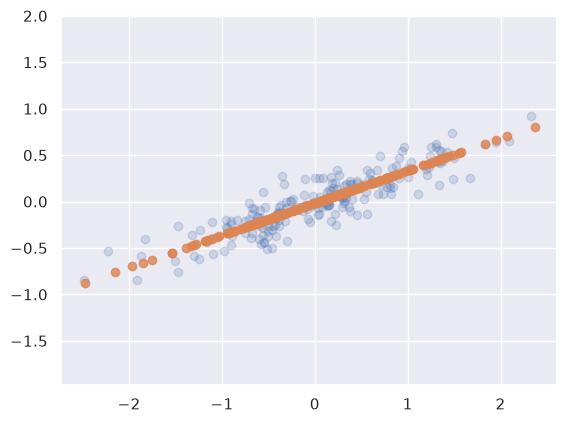

In [18]:
X_new = pca.inverse_transform(X_pca)
plt.scatter(X[:, 0], X[:, 1], alpha=0.2)
plt.scatter(X_new[:, 0], X_new[:, 1], alpha=0.8)
plt.axis('equal');

Los puntos azules son los datos originales, mientras que los datos naranja son los datos proyectados de vuelta sobre el espacio dimensional original utilizando como base normal los eigenvectores aprendidos

Podemos observar claramente qué pasa, al pasar los datos de ida y vuelta por el método, quita la información de la dimensión (o dimensiones) menos significativa(s).

El porcentaje de varianza explicada por los últimos componentes es la información que descartamos, pese a descartar la mitad de las dimensiones, podemos conservar de manera adecuada la relación de distancia entre los puntos

### PCA como herramienta para visualización

La utilidad percibida de PCA puede ser mayor el modelos de alta dimensionalidad.Importemos el dataset [digits](http://scikit-learn.org/stable/auto_examples/datasets/plot_digits_last_image.html)


In [19]:
from sklearn.datasets import load_digits
digits = load_digits()
digits.data.shape

(1797, 64)

In [20]:
digits.images[0]

array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.],
       [ 0.,  0., 13., 15., 10., 15.,  5.,  0.],
       [ 0.,  3., 15.,  2.,  0., 11.,  8.,  0.],
       [ 0.,  4., 12.,  0.,  0.,  8.,  8.,  0.],
       [ 0.,  5.,  8.,  0.,  0.,  9.,  8.,  0.],
       [ 0.,  4., 11.,  0.,  1., 12.,  7.,  0.],
       [ 0.,  2., 14.,  5., 10., 12.,  0.,  0.],
       [ 0.,  0.,  6., 13., 10.,  0.,  0.,  0.]])

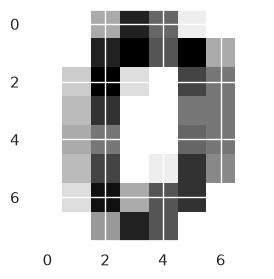

In [21]:
plt.figure(1, figsize=(3, 3))
plt.imshow(digits.images[0], cmap=plt.cm.gray_r, interpolation='nearest')

In [22]:
digits.target[0]

np.int64(0)

In [23]:
digits.images[32]

array([[ 0.,  2., 13., 16., 16., 16., 11.,  0.],
       [ 0.,  5., 16., 10.,  5.,  4.,  1.,  0.],
       [ 0.,  6., 16.,  7.,  3.,  0.,  0.,  0.],
       [ 0.,  9., 16., 16., 16.,  6.,  0.,  0.],
       [ 0.,  3.,  8.,  4., 11., 15.,  0.,  0.],
       [ 0.,  0.,  0.,  1., 12., 15.,  0.,  0.],
       [ 0.,  0.,  4., 13., 16.,  6.,  0.,  0.],
       [ 0.,  2., 16., 15.,  8.,  0.,  0.,  0.]])

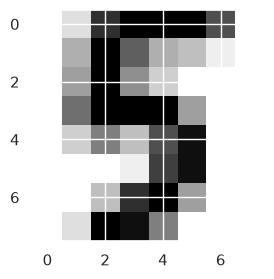

In [24]:
plt.figure(1, figsize=(3, 3))
plt.imshow(digits.images[32], cmap=plt.cm.gray_r, interpolation='nearest')

In [25]:
digits.target[32]

np.int64(5)

El dataset consiste en imágenes de 8x8 pixeles en escala de gris, que reflejan diferentes formas de escribir dígitos. Usemos PCA para reflejar estos datos 64 dimensionales en solo 2 dimensiones.


In [26]:
digits.data[0].shape

(64,)

In [27]:
pca = PCA(2)  # proyectar 64 pixeles en 2 dimensiones
model = pca.fit(digits.data)
projected = model.transform(digits.data)
print(digits.data.shape)
print(projected.shape)

(1797, 64)
(1797, 2)


In [28]:
pca.explained_variance_ratio_

array([0.14890594, 0.13618771])

In [29]:
projected[32]

array([-5.02024152,  3.59829263])

Dibujemos cada imagen en el espacio dimensional generado por las imágenes de los dígitos

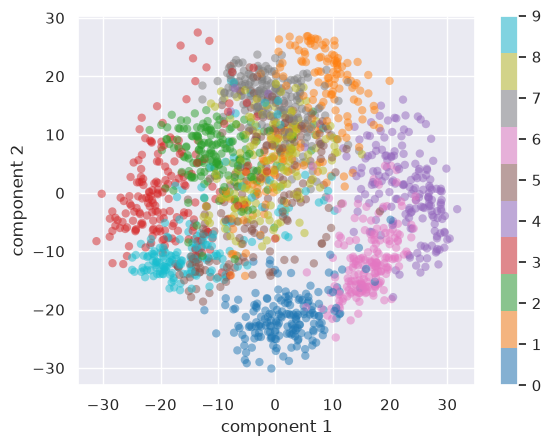

In [30]:
plt.scatter(projected[:, 0], projected[:, 1],
            c=digits.target, edgecolor='none', alpha=0.5,
            cmap=plt.get_cmap('tab10', 10))
plt.xlabel('component 1')
plt.ylabel('component 2')
plt.colorbar();

Estamos observando datos 64 dimensionales en 2 dimensiones, observe las distancias entre los dígitos y recuerde que no se utilizaron las etiquetas como herramienta para encontrar los eigenvectores sobre los cuales vamos a reflejar los datos.


## ¿Qué representa cada componente?

La transformación de cada dato depende de la tranformación de cada dato bajo cada eigenvector escogido. Consideremos $x$ como la imagen 64 dimensional:

$$
x = [x_1, x_2, x_3 \cdots x_{64}]
$$

Una forma mediante la cual podemos pensar en los eigenvectores como una base de transformación de pixeles unidimensional (pixel1, pixel2, pixel3, ..., pixel64). Para construir un pixel transformado podemos usar la base de transformación de pixel unidimensional y sumarlos uno a uno para la construcción de la imagen final.


$$
{\rm image}(x) = \bar{x} + x_1 \cdot{\rm (pixel~1)} + x_2 \cdot{\rm (pixel~2)} + x_3 \cdot{\rm (pixel~3)} \cdots x_{64} \cdot{\rm (pixel~64)}
$$


In [31]:
def plot_pca_components(x, coefficients=None, mean=0, components=None,
                        imshape=(8, 8), n_components=8, fontsize=12,
                        show_mean=True):
    if coefficients is None:
        coefficients = x

    if components is None:
        components = np.eye(len(coefficients), len(x))

    mean = np.zeros_like(x) + mean


    fig = plt.figure(figsize=(1.2 * (5 + n_components), 1.2 * 2))
    g = plt.GridSpec(2, 4 + bool(show_mean) + n_components, hspace=0.3)

    def show(i, j, x, title=None):
        ax = fig.add_subplot(g[i, j], xticks=[], yticks=[])
        ax.imshow(x.reshape(imshape), interpolation='nearest', cmap=plt.cm.gray_r,)
        if title:
            ax.set_title(title, fontsize=fontsize)

    show(slice(2), slice(2), x, "True")

    approx = mean.copy()

    counter = 2
    if show_mean:
        show(0, 2, np.zeros_like(x) + mean, r'$\mu$')
        show(1, 2, approx, r'$1 \cdot \mu$')
        counter += 1

    for i in range(n_components):
        approx = approx + coefficients[i] * components[i]
        show(0, i + counter, components[i], r'$c_{0}$'.format(i + 1))
        show(1, i + counter, approx,
             r"${0:.2f} \cdot c_{1}$".format(coefficients[i], i + 1))
        if show_mean or i > 0:
            plt.gca().text(0, 1.05, '$+$', ha='right', va='bottom',
                           transform=plt.gca().transAxes, fontsize=fontsize)

    show(slice(2), slice(-2, None), approx, "Approx")
    return fig


In [32]:
digits.data[10][0:8]

array([ 0.,  0.,  1.,  9., 15., 11.,  0.,  0.])

In [33]:
# Suponer que estos son eigenvectores
np.eye(len(digits.data[10][0:8]), len(digits.data[10][0:8]))

array([[1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1.]])

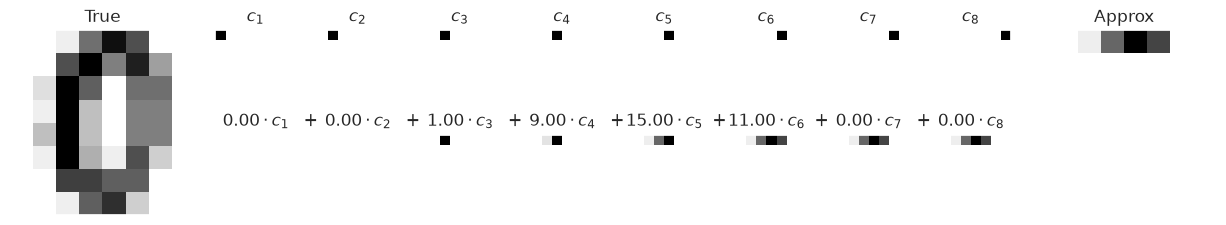

In [34]:
# Se reproyecta una parte de la instancia en los eigenvectores
fig = plot_pca_components(digits.data[10],
                          show_mean=False)

Usando solamente 8 bases de pixel, podemos reconstruir la parte superior de la imagen (la magnitud de la base esta representada por su intensidad)

Si usamos la base vectorial extraida (basis1, basis2, basis3,.. basis64) por pca, podemos construir una matriz de pixeles a partir de la contribución de cada base.

$$
image(x) = \bar{x} + x_1 \cdot{\rm (basis~1)} + x_2 \cdot{\rm (basis~2)} + x_3 \cdot{\rm (basis~3)} \cdots
$$

Si tomamos 8 bases, podemos realizar una proyección de los datos bajo una dimensionalidad reducida.

In [35]:
pca = PCA(n_components=15)
Xproj = pca.fit_transform(digits.data)
sns.set_style('white')


In [36]:
Xproj[10][0:8]

array([ 11.21507945, -16.91986211,  10.06684939,  -9.74708764,
         5.67341524,   8.10437792,   3.34263321,   7.12077254])

Text(0.5, 1.0, 'Primer componente')

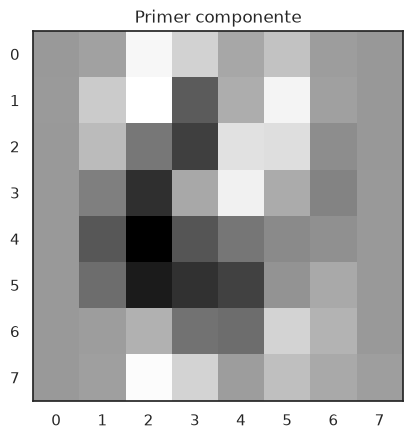

In [37]:
plt.imshow(pca.components_[0].reshape(8, 8), cmap=plt.cm.gray_r, interpolation='nearest')
plt.title('Primer componente')

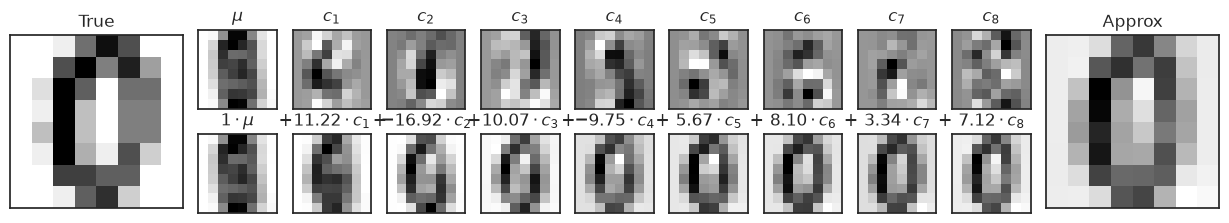

In [38]:
fig = plot_pca_components(digits.data[10], Xproj[10],
                          pca.mean_, pca.components_)

In [39]:
pca.components_.shape

(15, 64)

In [40]:
Xproj[10]

array([ 11.21507945, -16.91986211,  10.06684939,  -9.74708764,
         5.67341524,   8.10437792,   3.34263321,   7.12077254,
        -0.37527627,  -6.54202825,   2.48138894,   5.55984689,
         1.00337271,  -0.61705279,  -1.27318086])

In [41]:
pca.mean_.shape

(64,)

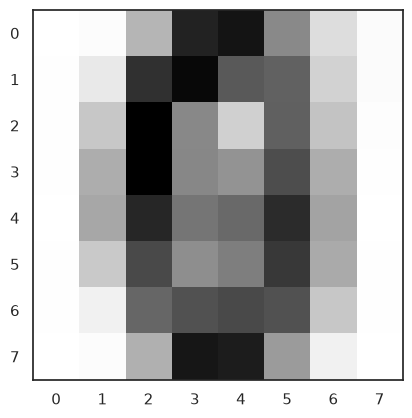

In [42]:
plt.imshow((pca.mean_+ Xproj[10][0]*pca.components_[0]+Xproj[10][1]*pca.components_[1]+Xproj[10][2]*pca.components_[2]+Xproj[10][3]*pca.components_[3]+pca.mean_).reshape((8,8)), interpolation='nearest', cmap=plt.cm.gray_r)

### Escogiendo las dimensiones adecuadas

Una parte vital de PCA es escoger el número de dimensiones en las cuales vamos a reducir.

Esto puede ser estimado mediante los valores de los eigenvalores, dado que nos cuentan cuánta varianza estan recogiendo del dataset original.

En sklearn, podemos observar el atributo ``explained_variance_ratio``

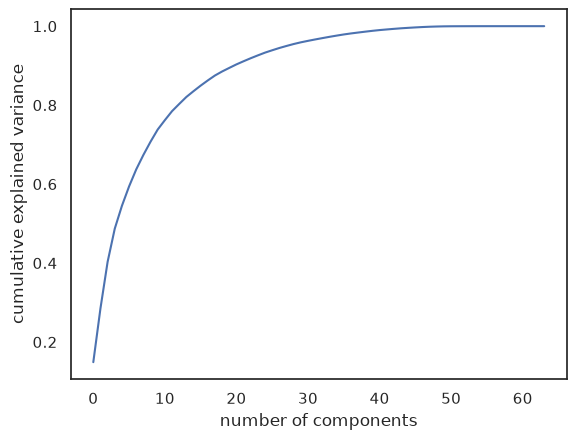

In [43]:
pca = PCA().fit(digits.data)
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance');

In [44]:
np.round(pca.explained_variance_ratio_,4)

array([1.489e-01, 1.362e-01, 1.179e-01, 8.410e-02, 5.780e-02, 4.920e-02,
       4.320e-02, 3.660e-02, 3.350e-02, 3.080e-02, 2.370e-02, 2.270e-02,
       1.820e-02, 1.770e-02, 1.470e-02, 1.410e-02, 1.320e-02, 1.250e-02,
       1.020e-02, 9.100e-03, 8.900e-03, 8.000e-03, 7.700e-03, 7.200e-03,
       7.000e-03, 6.000e-03, 5.800e-03, 5.200e-03, 4.900e-03, 4.300e-03,
       3.700e-03, 3.500e-03, 3.400e-03, 3.300e-03, 3.100e-03, 2.900e-03,
       2.600e-03, 2.300e-03, 2.200e-03, 2.100e-03, 1.900e-03, 1.600e-03,
       1.500e-03, 1.400e-03, 1.200e-03, 1.100e-03, 1.000e-03, 8.000e-04,
       6.000e-04, 4.000e-04, 2.000e-04, 1.000e-04, 1.000e-04, 1.000e-04,
       0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
       0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00])

In [45]:
pca.components_[:,0:10].shape

(64, 10)

In [46]:
np.round(np.cumsum(pca.explained_variance_ratio_),4)

array([0.1489, 0.2851, 0.403 , 0.4871, 0.545 , 0.5941, 0.6373, 0.6739,
       0.7074, 0.7382, 0.762 , 0.7847, 0.8029, 0.8206, 0.8353, 0.8494,
       0.8626, 0.8751, 0.8852, 0.8943, 0.9032, 0.9112, 0.9188, 0.9261,
       0.933 , 0.939 , 0.9447, 0.9499, 0.9548, 0.9591, 0.9628, 0.9664,
       0.9697, 0.973 , 0.9761, 0.979 , 0.9816, 0.9839, 0.9861, 0.9882,
       0.9901, 0.9917, 0.9932, 0.9946, 0.9958, 0.9968, 0.9978, 0.9986,
       0.9991, 0.9995, 0.9998, 0.9998, 0.9999, 0.9999, 1.    , 1.    ,
       1.    , 1.    , 1.    , 1.    , 1.    , 1.    , 1.    , 1.    ])

La curva nos indica cumulativamente cuánta varianza acumula cada componente en los primeros $N$ componentes.

Por ejemplo, los primeros 10 componentes acumulan alrededor de 75% del total de la varianza y alrededor de 20 componentes ya tenemos representada alrededor de 90% de la varianza, también vemos que a partir del componente 50 ya se recoge el 100% de la varianza original de los datos.


## PCA como herramienta para reducción de ruido

PCA puede ser utilizado para reducir el ruido de información ruidosa
La principal idea es, los datos que no se ven reflejados facilmente por la reducción dimensional deben ser datos con ruido, por lo tanto al descartar las ultimas dimensiones estamos descartando en parte el ruido sobre el conjunto de datos.

Revisemos esto sobre el dataset de dígitos

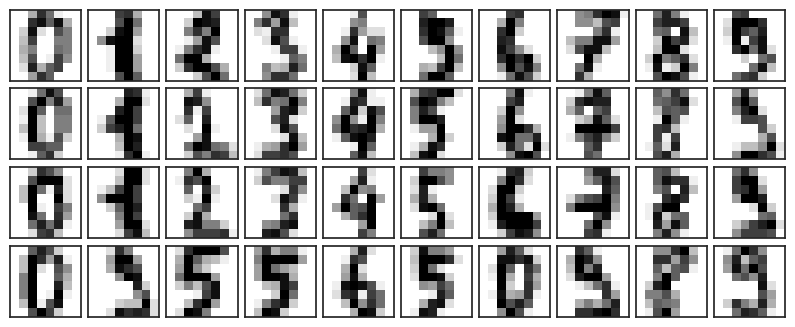

In [47]:
def plot_digits(data):
    fig, axes = plt.subplots(4, 10, figsize=(10, 4),
                             subplot_kw={'xticks':[], 'yticks':[]},
                             gridspec_kw=dict(hspace=0.1, wspace=0.1))
    for i, ax in enumerate(axes.flat):
        ax.imshow(data[i].reshape(8, 8),
                  cmap='binary', interpolation='nearest',
                  clim=(0, 16))
plot_digits(digits.data)

Ahora añadamos ruido y repitamos el proceso

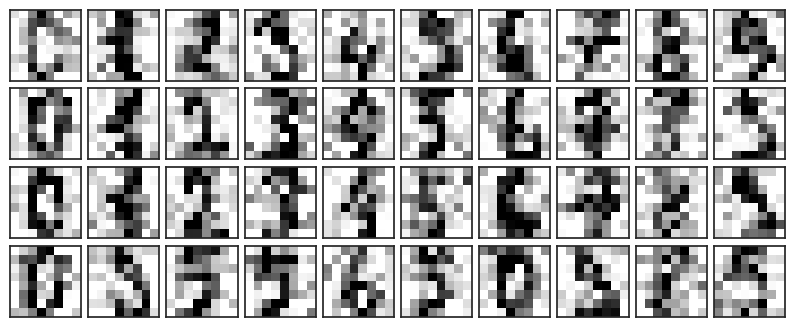

In [48]:
np.random.seed(42)
noisy = np.random.normal(digits.data, 4)
plot_digits(noisy)

Es fácil distiguir que hay pixeles con ruido en algunas imágenes

Entrenemos PCA sobre los datos con ruido, conservando el 50% de la varianza.

In [49]:
pca_2 = PCA(0.50).fit(noisy)
pca_2.n_components_

np.int64(12)

El 50% de la varianza corresponde a 12 componentes principales. Reproyectemos las imágenes sobre el espacio original de vuelta utilizando lo aprendido

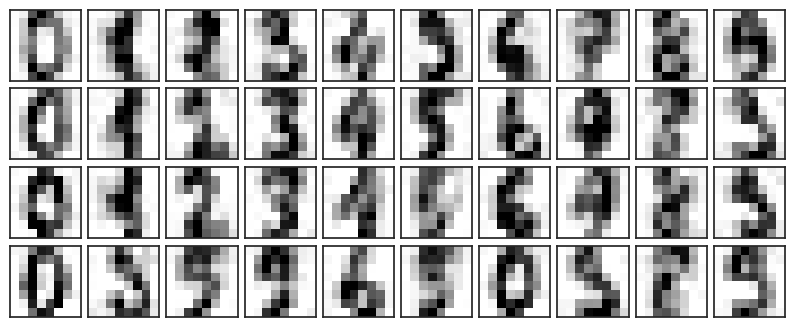

In [50]:
components = pca_2.transform(noisy)
filtered = pca_2.inverse_transform(components)
plot_digits(filtered)

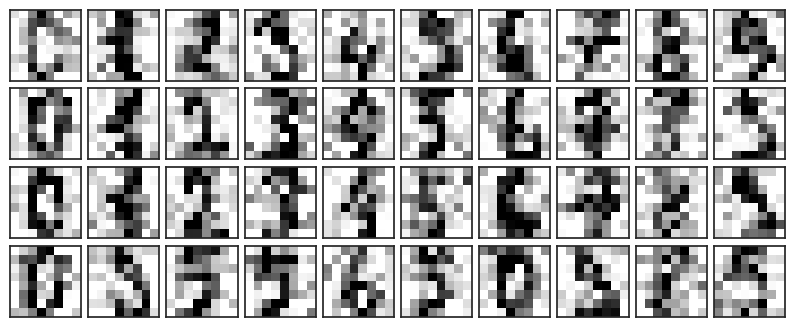

In [51]:
components = pca.transform(noisy)
filtered = pca.inverse_transform(components)
plot_digits(filtered)

Esta propiedad de reducción de ruido nos permite utilizar, por ejemplo, modelos supervisados para clasificación o regresión, retirando de los datos posible ruido sobre la señal

## Example: Eigenfaces

Vamos a tomar algunas imágenes del dataset de fotos de scikitlearn y vamos a aprender una representación de menor dimensionalidad sobre los datos,


In [52]:
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=70)
print(faces.target_names)
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Tony Blair']
(1288, 62, 47)


In [53]:
62*47

2914

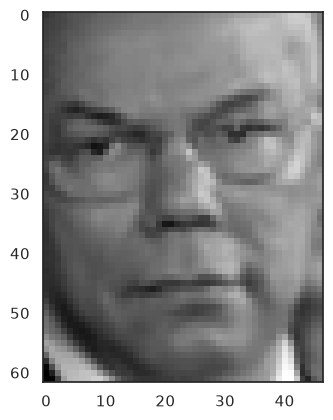

In [54]:
plt.imshow(faces.images[5],
                  cmap='binary_r', interpolation='nearest',
                  )

Realicemos una descomposición PCA de las imágenes y revisemos el resultado que obtenemos. Como este dataset es un poco más grande, vamos a usar otra técnica llamada Randomized PCA. Randomized PCA aproxima un número determinado de componentes mediante el muestreo de partes de X y la aplicación de modelos de factorización de matrices (parecido a SVD)

Tomaremos entonces los primeros 150 componentes:

In [55]:

pca = PCA(150, svd_solver='randomized')
pca.fit(faces.data)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",150
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'randomized'
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomi

En este caso queremos observar las imágenes asociadas a los primeros componentes (eigenvectores). A estas imágenes se les conoce como "eigencaras" (eigenfaces) por la comunidad de reconocimiento de imágenes en los 80's.

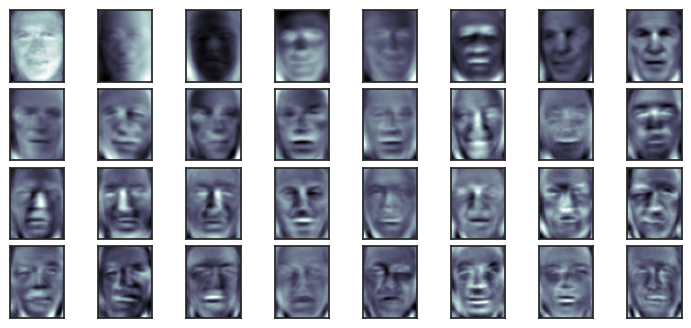

In [56]:
fig, axes = plt.subplots(4, 8, figsize=(9, 4),
                         subplot_kw={'xticks':[], 'yticks':[]},
                         gridspec_kw=dict(hspace=0.1, wspace=0.1))
for i, ax in enumerate(axes.flat):
    ax.imshow(pca.components_[i].reshape(62, 47), cmap='bone')

Al revisar la distribución cumulativa de la varianza, podemos observar que el 90% de la varianza de las imágenes se mantiene con 150 dimensiones.

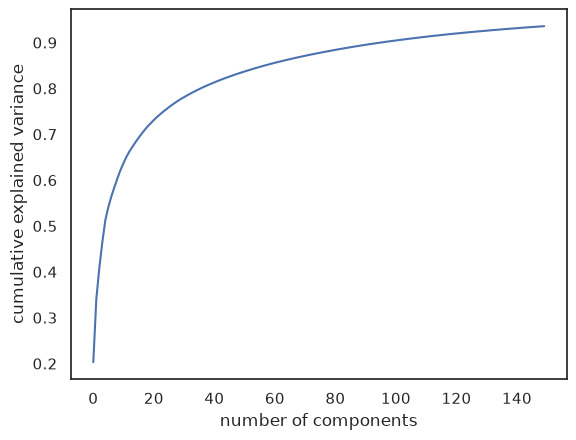

In [57]:
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance');

Comparemos entonces las imágenes originales vs las imágenes transformadas de vuelta utilizando los vectores encontrados.

In [58]:
print(f'Foto original mide {faces.data[0].shape}')
# Components tiene las imágenes reducidas a 150 dimensiones
components = pca.transform(faces.data)
print(f'Foto reducida mide {components[0].shape}')
# Inverse transform vuelve y refleja cada elemento de 150 dimensiones en el espacio original
projected = pca.inverse_transform(components)
print(f'Foto reproyectada mide {projected[0].shape}')

Foto original mide (2914,)
Foto reducida mide (150,)
Foto reproyectada mide (2914,)


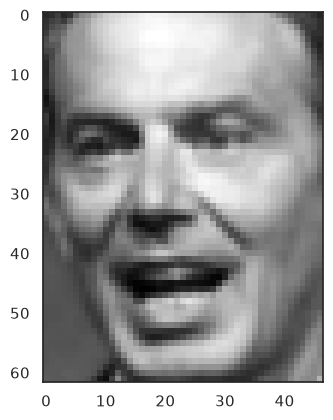

In [59]:
plt.imshow(faces.data[1].reshape(62, 47), cmap='binary_r')

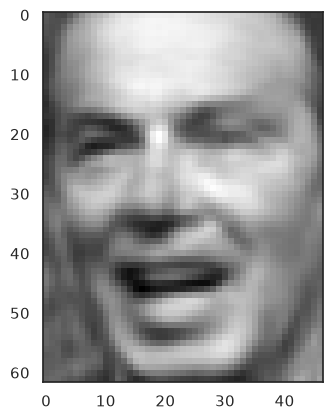

In [60]:
plt.imshow(projected[1].reshape(62, 47), cmap='binary_r')

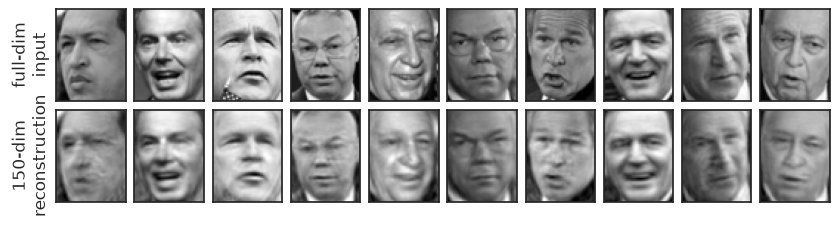

In [61]:
# Plot the results
fig, ax = plt.subplots(2, 10, figsize=(10, 2.5),
                       subplot_kw={'xticks':[], 'yticks':[]},
                       gridspec_kw=dict(hspace=0.1, wspace=0.1))
for i in range(10):
    ax[0, i].imshow(faces.data[i].reshape(62, 47), cmap='binary_r')
    ax[1, i].imshow(projected[i].reshape(62, 47), cmap='binary_r')

ax[0, 0].set_ylabel('full-dim\ninput')
ax[1, 0].set_ylabel('150-dim\nreconstruction');

Al reducir la dimensionalidad, podemos por ejemplo correr un algoritmo de aprendizaje supervisado sobre las imágenes para detectar de quién se trata.

In [62]:
faces.target

array([5, 6, 3, ..., 5, 3, 5], shape=(1288,))

In [63]:
faces.target_names

array(['Ariel Sharon', 'Colin Powell', 'Donald Rumsfeld', 'George W Bush',
       'Gerhard Schroeder', 'Hugo Chavez', 'Tony Blair'], dtype='<U17')

In [64]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(
    faces.data, faces.target, test_size=0.2, random_state=42, stratify=faces.target)
# Transformamos datos
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)

param_grid = {'C': [1e3, 5e3, 1e4, 5e4, 1e5],
              'gamma': [0.001,0.005, 0.01, 0.1,'scale'], }
clf = GridSearchCV(
    SVC(kernel='rbf', class_weight='balanced'), param_grid
)
clf = clf.fit(X_train_pca, y_train)

print(clf.best_estimator_)

y_pred = clf.best_estimator_.predict(X_test_pca)
print(classification_report(y_test, y_pred, target_names=faces.target_names))
n_classes = faces.target_names.shape[0]
print(confusion_matrix(y_test, y_pred, labels=range(n_classes)))


SVC(C=1000.0, class_weight='balanced', gamma=0.005)
                   precision    recall  f1-score   support

     Ariel Sharon       0.73      0.69      0.71        16
     Colin Powell       0.79      0.94      0.85        47
  Donald Rumsfeld       0.71      0.62      0.67        24
    George W Bush       0.87      0.88      0.87       106
Gerhard Schroeder       0.75      0.82      0.78        22
      Hugo Chavez       0.90      0.64      0.75        14
       Tony Blair       0.92      0.79      0.85        29

         accuracy                           0.83       258
        macro avg       0.81      0.77      0.78       258
     weighted avg       0.83      0.83      0.82       258

[[11  0  1  2  1  1  0]
 [ 1 44  0  1  0  0  1]
 [ 0  2 15  5  1  0  1]
 [ 0  8  4 93  1  0  0]
 [ 1  0  1  2 18  0  0]
 [ 1  1  0  2  1  9  0]
 [ 1  1  0  2  2  0 23]]


## Ejercicio

En esta sección hemos visto cómo utilizar PCA para visualizar un conjunto de datos multidimensional, y para correr modelos de clasificación y regresión de forma más sencilla, ya que disminuimos la complejidad computacional de los métodos utilizados.

La idea del ejercicio es realizar el análisis de varianza, visualización y clasificación (con el método que considere conveniente)

In [65]:
from sklearn.datasets import load_breast_cancer

breast_cancer=load_breast_cancer(as_frame=True)

In [66]:
breast_cancer.data

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [67]:
import pandas as pd
from IPython.display import display

# Estilo general para poder ponerle a las tablas y que se entiendan mas
ESTILO_TABLAS = [
    {'selector': 'caption',
     'props': 'caption-side: top; font-size: 15px; font-weight: bold; '
              'color: #2c3e50; background-color: #ecf0f1; padding: 8px;'},
    {'selector': 'th',
     'props': 'background-color: #34495e; color: white; text-align: center; '
              'padding: 6px 10px; border: 1px solid #2c3e50;'},
    {'selector': 'td',
     'props': 'text-align: center; padding: 6px 10px; border: 1px solid #dfe6e9;'},
    {'selector': 'tbody tr:hover td, tbody tr:hover th',
     'props': 'background-color: #ffe082 !important; color: #2c3e50 !important; '
              'font-weight: bold; cursor: pointer;'},
    {'selector': '',
     'props': 'border-collapse: collapse; margin: 10px 0 20px 0;'},
]


def fondo_base(data):
    return pd.DataFrame(
        [[f"background-color: {'#f2f5f7' if i % 2 else '#ffffff'}; color: #2c3e50;"]
         * data.shape[1] for i in range(data.shape[0])],
        index=data.index, columns=data.columns,
    )


def mostrar_tabla(df, titulo, formato='{:.4f}', gradiente=None, cmap='Blues',
                  eje_gradiente=0, ocultar_indice=False, resaltar_max=None):
    numericas = df.select_dtypes('number').columns
    estilo = (
        df.style.set_caption(titulo)
        .set_table_styles(ESTILO_TABLAS)
        .apply(fondo_base, axis=None)
    )
    if isinstance(formato, dict):
        estilo = estilo.format(formato)
    else:
        estilo = estilo.format(formato, subset=numericas)
    if gradiente is not None:
        columnas = numericas if gradiente == 'todo' else gradiente
        estilo = estilo.background_gradient(subset=columnas, cmap=cmap, axis=eje_gradiente)
    if resaltar_max is not None:
        estilo = estilo.highlight_max(subset=resaltar_max,
                                      props='background-color: #c8e6c9; color: #1b5e20; font-weight: bold;')
    if ocultar_indice:
        estilo = estilo.hide(axis='index')
    display(estilo)

### Preparación de los datos

El conjunto de datos de cáncer de mama contiene 569 observaciones descritas por 30 variables numéricas que caracterizan los núcleos celulares de cada muestra, junto con una etiqueta binaria que indica si el tumor es maligno o benigno. Antes de aplicar PCA es necesario normalizar los datos, ya que el método busca las direcciones de máxima varianza a partir de la matriz de covarianza. Si las variables se dejan en sus escalas originales, aquellas con magnitudes grandes dominarían la varianza total y, en consecuencia, también los primeros componentes principales. Por esta razón se estandarizan las variables para que tengan media 0 y varianza 1.

In [68]:
from sklearn.preprocessing import StandardScaler

X = breast_cancer.data
y = breast_cancer.target

conteo = (y.value_counts()
            .rename(index=dict(enumerate(breast_cancer.target_names)))
            .to_frame('Observaciones'))
conteo['Porcentaje'] = conteo['Observaciones'] / conteo['Observaciones'].sum()
mostrar_tabla(conteo, f'Distribución de clases ({X.shape[0]} observaciones, {X.shape[1]} variables)',
              formato={'Observaciones': '{:d}', 'Porcentaje': '{:.1%}'})

X_std = StandardScaler().fit_transform(X)

,Observaciones,Porcentaje
target,,
benign,357,62.7%
malignant,212,37.3%


In [69]:
# Efecto de no normalizar: PCA sobre los datos en su escala original
pca_raw = PCA().fit(X)
comparacion = pd.DataFrame({
    'Sin normalizar': pca_raw.explained_variance_ratio_[:3],
    'Normalizado': PCA().fit(X_std).explained_variance_ratio_[:3],
}, index=['PC1', 'PC2', 'PC3'])
mostrar_tabla(comparacion, 'Varianza explicada: datos originales vs. normalizados',
              formato='{:.2%}', gradiente='todo', cmap='Oranges', eje_gradiente=None)
print('Variable con mayor peso en PC1 (sin normalizar):',
      X.columns[np.argmax(np.abs(pca_raw.components_[0]))])

,Sin normalizar,Normalizado
PC1,98.20%,44.27%
PC2,1.62%,18.97%
PC3,0.16%,9.39%


Variable con mayor peso en PC1 (sin normalizar): worst area


Como se observa, sin normalizar el primer componente acapara cerca del 98% de la varianza y está dominado casi por completo por la variable *worst area*, que es simplemente la de mayor escala. Esto confirma que el análisis debe hacerse sobre los datos estandarizados.

### Análisis de varianza

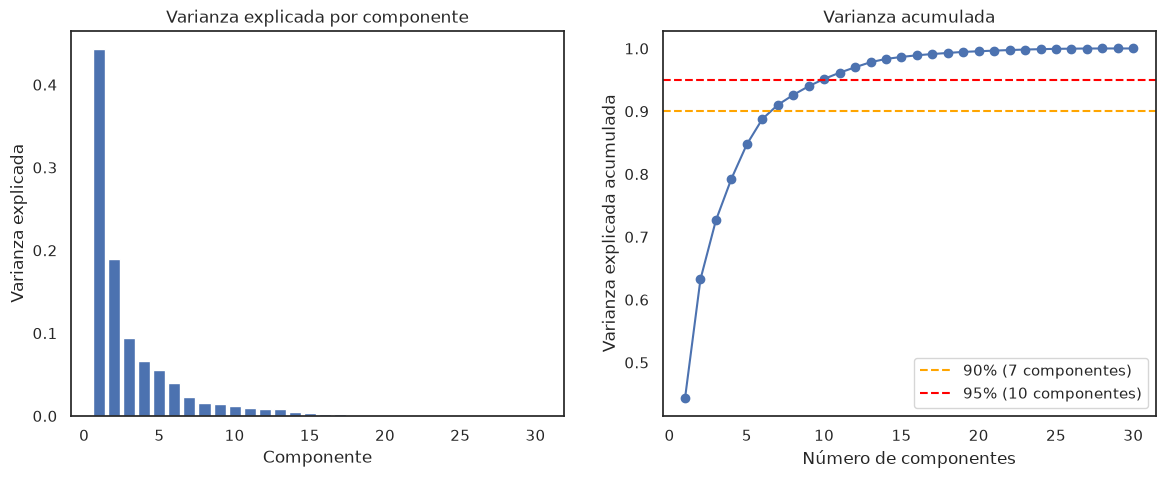

,Eigenvalor,Varianza explicada,Varianza acumulada,Umbral
PC1,13.305,44.27%,44.27%,
PC2,5.701,18.97%,63.24%,
PC3,2.823,9.39%,72.64%,
PC4,1.984,6.60%,79.24%,
PC5,1.652,5.50%,84.73%,
PC6,1.209,4.02%,88.76%,
PC7,0.676,2.25%,91.01%,≥ 90%
PC8,0.477,1.59%,92.60%,
PC9,0.418,1.39%,93.99%,
PC10,0.351,1.17%,95.16%,≥ 95%


In [70]:
pca_bc = PCA().fit(X_std)
var_acum = np.cumsum(pca_bc.explained_variance_ratio_)

n_90 = np.argmax(var_acum >= 0.90) + 1
n_95 = np.argmax(var_acum >= 0.95) + 1

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
componentes = np.arange(1, len(var_acum) + 1)
ax[0].bar(componentes, pca_bc.explained_variance_ratio_)
ax[0].set(xlabel='Componente', ylabel='Varianza explicada', title='Varianza explicada por componente')

ax[1].plot(componentes, var_acum, marker='o')
ax[1].axhline(0.90, color='orange', linestyle='--', label=f'90% ({n_90} componentes)')
ax[1].axhline(0.95, color='red', linestyle='--', label=f'95% ({n_95} componentes)')
ax[1].set(xlabel='Número de componentes', ylabel='Varianza explicada acumulada', title='Varianza acumulada')
ax[1].legend()
plt.show()

tabla_var = pd.DataFrame({
    'Eigenvalor': pca_bc.explained_variance_,
    'Varianza explicada': pca_bc.explained_variance_ratio_,
    'Varianza acumulada': var_acum,
}, index=[f'PC{i}' for i in componentes])
tabla_var['Umbral'] = ''
tabla_var.loc[f'PC{n_90}', 'Umbral'] = '≥ 90%'
tabla_var.loc[f'PC{n_95}', 'Umbral'] = '≥ 95%'

mostrar_tabla(tabla_var.head(12),
              f'Análisis de varianza (primeros 12 de {len(componentes)} componentes)',
              formato={'Eigenvalor': '{:.3f}', 'Varianza explicada': '{:.2%}',
                       'Varianza acumulada': '{:.2%}'},
              gradiente=['Varianza explicada', 'Varianza acumulada'])

In [71]:
cargas = pd.DataFrame(pca_bc.components_[:2].T, index=X.columns, columns=['PC1', 'PC2'])

top_pc1 = cargas.loc[cargas['PC1'].abs().sort_values(ascending=False).index[:5]]
top_pc2 = cargas.loc[cargas['PC2'].abs().sort_values(ascending=False).index[:5]]

mostrar_tabla(top_pc1, 'Variables con mayor peso en PC1', formato='{:.3f}',
              gradiente='todo', cmap='RdBu_r', eje_gradiente=None)
mostrar_tabla(top_pc2, 'Variables con mayor peso en PC2', formato='{:.3f}',
              gradiente='todo', cmap='RdBu_r', eje_gradiente=None)

,PC1,PC2
mean concave points,0.261,-0.035
mean concavity,0.258,0.060
worst concave points,0.251,-0.008
mean compactness,0.239,0.152
worst perimeter,0.237,-0.200


,PC1,PC2
mean fractal dimension,0.064,0.367
fractal dimension error,0.103,0.280
worst fractal dimension,0.132,0.275
mean radius,0.219,-0.234
compactness error,0.170,0.233


El análisis de los eigenvalores muestra que la varianza está muy concentrada en los primeros componentes. El primero explica alrededor del 44,3% de la varianza total y el segundo cerca del 19%, de modo que entre ambos ya se recoge aproximadamente el 63%. Con 7 componentes se supera el 90% de la varianza y con 10 componentes se alcanza el 95%, lo que significa que las 30 variables originales pueden representarse en un espacio de un tercio de su tamaño perdiendo apenas un 5% de la información. Esto es coherente con la alta correlación que existe entre varias de las variables del dataset, ya que muchas de ellas miden propiedades muy parecidas del núcleo y cada característica aparece en su versión media, de error y de peor valor. Hay entonces mucha redundancia, y PCA la aprovecha al construir ejes ortogonales y descorrelacionados.

Al revisar los eigenvectores se puede interpretar cada componente. El primero tiene pesos positivos y similares en las variables asociadas al tamaño y a la irregularidad del contorno del núcleo, por lo que puede entenderse como un eje general de tamaño e irregularidad celular. El segundo componente, en cambio, está dominado por las variables de dimensión fractal y tiene un peso negativo en el radio, de modo que captura una dirección distinta, relacionada con la complejidad del borde y no con el tamaño.

### Visualización

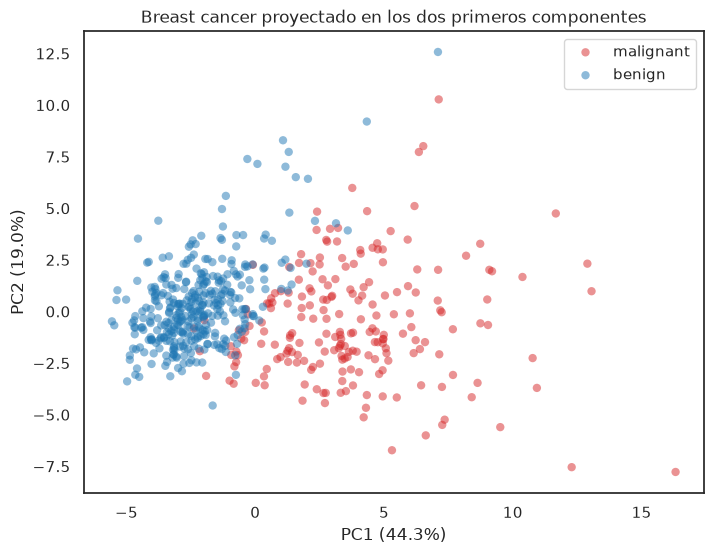

In [72]:
X_pca2 = pca_bc.transform(X_std)[:, :2]

plt.figure(figsize=(8, 6))
for clase, color in zip([0, 1], ['tab:red', 'tab:blue']):
    mask = y == clase
    plt.scatter(X_pca2[mask, 0], X_pca2[mask, 1], c=color, alpha=0.5,
                edgecolor='none', label=breast_cancer.target_names[clase])
plt.xlabel(f'PC1 ({pca_bc.explained_variance_ratio_[0]:.1%})')
plt.ylabel(f'PC2 ({pca_bc.explained_variance_ratio_[1]:.1%})')
plt.title('Breast cancer proyectado en los dos primeros componentes')
plt.legend()
plt.show()

Al proyectar los datos de 30 dimensiones sobre los dos primeros componentes se observa que las dos clases quedan bastante bien separadas, aun cuando PCA no utilizó las etiquetas para encontrar los eigenvectores. Los tumores malignos se ubican mayoritariamente hacia valores altos del primer componente y presentan una dispersión mayor, mientras que los benignos se concentran hacia valores bajos y forman un grupo más compacto. Esto indica que la dirección de máxima varianza de los datos coincide en buena medida con la dirección que distingue ambos diagnósticos, lo cual tiene sentido con la interpretación del primer componente como eje de tamaño e irregularidad celular. Existe una zona de traslape entre ambas clases cerca del centro del gráfico, donde se esperaría que ocurran la mayoría de los errores de un clasificador.

### Clasificación

Para la clasificación se utiliza una regresión logística, dado que el problema es binario y la visualización anterior sugiere que las clases son casi linealmente separables en el espacio de componentes principales. El primer modelo se entrena con las 30 variables originales y sirve como referencia. El segundo utiliza los componentes que retienen el 95% de la varianza, y el tercero trabaja únicamente con los dos componentes que se visualizaron en el gráfico anterior. En los tres casos la normalización y PCA se incluyen dentro de un `Pipeline`, de forma que se ajustan únicamente con los datos de entrenamiento, y el hiperparámetro de regularización `C` se elige con validación cruzada mediante `GridSearchCV`.

In [73]:
import time
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

escenarios = {
    'Sin PCA (30 variables)': [('scaler', StandardScaler()),
                               ('clf', LogisticRegression(max_iter=5000))],
    'PCA 95% de varianza':    [('scaler', StandardScaler()), ('pca', PCA(0.95)),
                               ('clf', LogisticRegression(max_iter=5000))],
    'PCA 2 componentes':      [('scaler', StandardScaler()), ('pca', PCA(2)),
                               ('clf', LogisticRegression(max_iter=5000))],
}
param_grid_lr = {'clf__C': [0.01, 0.1, 1, 10, 100]}

resultados = []
modelos = {}
for nombre, pasos in escenarios.items():
    inicio = time.time()
    grid = GridSearchCV(Pipeline(pasos), param_grid_lr, cv=5).fit(X_train, y_train)
    tiempo = time.time() - inicio
    y_pred = grid.predict(X_test)
    pca_paso = grid.best_estimator_.named_steps.get('pca')
    resultados.append({
        'Escenario': nombre,
        'Dimensiones': pca_paso.n_components_ if pca_paso is not None else X.shape[1],
        'Mejor C': grid.best_params_['clf__C'],
        'Accuracy CV': round(grid.best_score_, 4),
        'Accuracy test': round((y_pred == y_test).mean(), 4),
        'Tiempo (s)': round(tiempo, 3),
    })
    modelos[nombre] = y_pred

mostrar_tabla(pd.DataFrame(resultados).set_index('Escenario'),
              'Comparación de modelos de regresión logística',
              formato={'Mejor C': '{:g}', 'Accuracy CV': '{:.2%}',
                       'Accuracy test': '{:.2%}', 'Tiempo (s)': '{:.3f}'},
              resaltar_max=['Accuracy CV', 'Accuracy test'])

,Dimensiones,Mejor C,Accuracy CV,Accuracy test,Tiempo (s)
Escenario,,,,,
Sin PCA (30 variables),30,0.1,98.02%,97.37%,0.238
PCA 95% de varianza,10,0.1,98.24%,97.37%,2.690
PCA 2 componentes,2,1,96.04%,94.74%,1.806


In [74]:
nombres_clases = list(breast_cancer.target_names)

for nombre, y_pred in modelos.items():
    reporte = pd.DataFrame(classification_report(
        y_test, y_pred, target_names=nombres_clases, output_dict=True)).T
    reporte = reporte.drop(index='accuracy').drop(columns='support')
    mostrar_tabla(reporte, f'Reporte de clasificación: {nombre}',
                  formato='{:.2f}',
                  gradiente=['precision', 'recall', 'f1-score'], cmap='Greens')

    matriz = pd.DataFrame(confusion_matrix(y_test, y_pred),
                          index=[f'Real: {c}' for c in nombres_clases],
                          columns=[f'Predicho: {c}' for c in nombres_clases])
    mostrar_tabla(matriz, f'Matriz de confusión: {nombre}', formato='{:d}',
                  gradiente='todo', eje_gradiente=None)

,precision,recall,f1-score
malignant,0.98,0.95,0.96
benign,0.97,0.99,0.98
macro avg,0.97,0.97,0.97
weighted avg,0.97,0.97,0.97


,Predicho: malignant,Predicho: benign
Real: malignant,40,2
Real: benign,1,71


,precision,recall,f1-score
malignant,0.98,0.95,0.96
benign,0.97,0.99,0.98
macro avg,0.97,0.97,0.97
weighted avg,0.97,0.97,0.97


,Predicho: malignant,Predicho: benign
Real: malignant,40,2
Real: benign,1,71


,precision,recall,f1-score
malignant,0.91,0.95,0.93
benign,0.97,0.94,0.96
macro avg,0.94,0.95,0.94
weighted avg,0.95,0.95,0.95


,Predicho: malignant,Predicho: benign
Real: malignant,40,2
Real: benign,4,68


Los resultados muestran que reducir la dimensionalidad con PCA no deteriora el desempeño del clasificador. El modelo con las 30 variables originales y el modelo con los 10 componentes que conservan el 95% de la varianza obtienen la misma exactitud sobre el conjunto de prueba, alrededor del 97,4%, y la misma matriz de confusión, con solo dos tumores malignos clasificados como benignos y uno benigno clasificado como maligno. Incluso en validación cruzada el modelo con PCA queda ligeramente por encima. Con un tercio de las dimensiones se conserva prácticamente toda la información relevante para el diagnóstico, se elimina la multicolinealidad entre las variables originales y se reduce la complejidad del modelo. En cuanto al tiempo de ejecución, en un dataset tan pequeño como este no se aprecia una ganancia, ya que el costo de calcular PCA en cada partición de la validación cruzada es comparable o mayor que el de entrenar la regresión logística con las 30 variables. La ventaja computacional de trabajar en un espacio reducido se vuelve relevante con conjuntos de datos de mayor tamaño o con modelos más costosos, como se vio en el ejemplo de eigenfaces.

El modelo que usa únicamente los dos primeros componentes alcanza una exactitud cercana al 94,7%, lo cual es notable considerando que trabaja con solo el 63% de la varianza y con dos de las treinta dimensiones originales. Su pérdida de desempeño se concentra en algunos tumores benignos que caen en la zona de traslape observada en la visualización. Esto confirma que la mayor parte de la capacidad discriminante del dataset está en los primeros componentes, y que escoger el número de componentes con el criterio de retener entre el 90% y el 95% de la varianza ofrece un buen equilibrio entre simplicidad del modelo y calidad de la clasificación.